# Predicting Employee Attrition Using Machine Learning

**Data Mining Final Project**

[Dataset: IBM HR Analytics Employee Attrition & Performance (Kaggle)](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

Run the code cells from top to bottom in Google Colab or Jupyter Notebook.

## 1. Load and inspect the dataset

Download the IBM HR Analytics dataset from Kaggle. The goal is to predict `Attrition`: 1 means the employee left, and 0 means the employee stayed.

In [ ]:
# Load the data and inspect its size, columns and target variable.
import pandas as pd
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

print("Path to dataset files:", path)

df = pd.read_csv(path + "/WA_Fn-UseC_-HR-Employee-Attrition.csv")

print(df.shape)
print(df.head(10))
df.info()
print(df["Attrition"].value_counts())


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Path to dataset files: /kaggle/input/ibm-hr-analytics-attrition-dataset
(1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   
5   32        No  Travel_Frequently       1005  Research & Development   
6   59        No      Travel_Rarely       1324  Research & Development   
7   30        No      Travel_Rarely       1358  Research & Development   
8   38        No  Travel_Frequently        216  Research & Development   
9   36        No      Travel_Rarely       1299  Research & Development   

   DistanceFr

## 2. Clean the data

Check missing values, duplicate rows and constant columns. Remove the employee ID and the three constant columns. Keep the original dataset unchanged.

In [ ]:
# Check the original data before cleaning.
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check columns with only one unique value
print("\nConstant Columns:")
print(df.columns[df.nunique() == 1].tolist())


Missing Values:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole      

In [ ]:
# Create a clean copy and convert the target to 0 and 1.
# Create a cleaned copy of the original dataset
df_clean = df.copy()

# Remove unnecessary columns
df_clean = df_clean.drop(columns=[
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
])

# Convert target variable to binary values
df_clean["Attrition"] = df_clean["Attrition"].map({
    "Yes": 1,
    "No": 0
}).astype(int)

# Compare before and after cleaning
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

# Verify results
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Missing Target Values:", df_clean["Attrition"].isnull().sum())

print("\nAttrition Distribution:")
print(df_clean["Attrition"].value_counts())

display(df_clean.head())


## 3. Split the dataset and explore employee attrition

Use a stratified 80/20 split to preserve the proportion of employees who left. The first chart shows the full dataset; the remaining exploratory charts use only the training records.

In [ ]:
# Keep 20% of the data separate for final testing.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["Attrition"]
)

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

sns.set_theme(style="whitegrid")


Training Dataset: (1176, 31)
Testing Dataset: (294, 31)


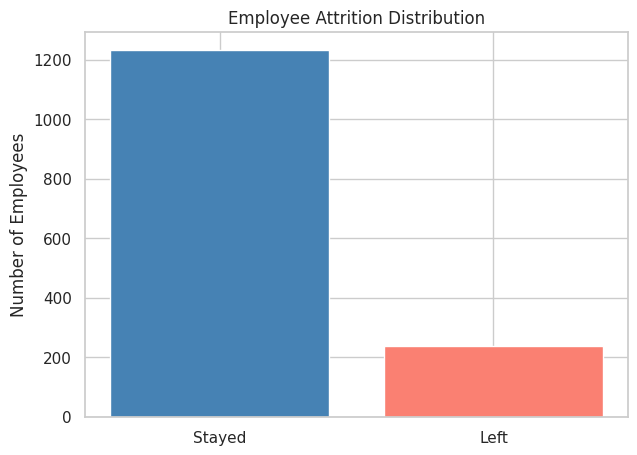

In [ ]:
# Count the employees who stayed and those who left.
counts = df_clean["Attrition"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(["Stayed", "Left"], counts.values,
        color=["steelblue", "salmon"])

plt.title("Employee Attrition Distribution")
plt.ylabel("Number of Employees")
plt.show()


OverTime
No     11.12
Yes    28.53
Name: Attrition, dtype: float64


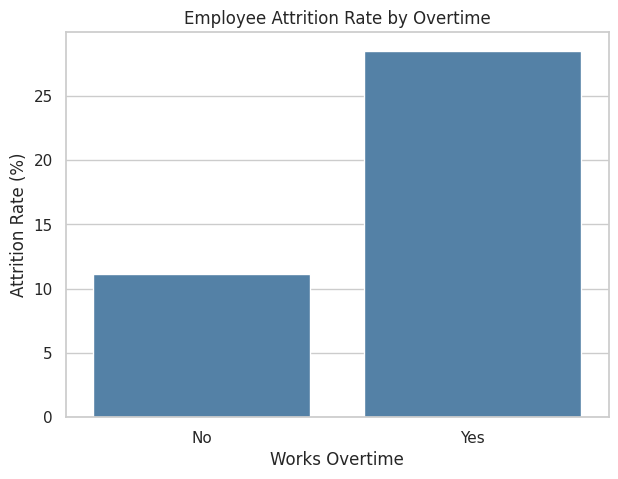

In [ ]:
# Calculate the percentage of employees who left in each overtime group.
overtime_attrition = (
    train_df.groupby("OverTime")["Attrition"].mean() * 100
)

print(overtime_attrition.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    x=overtime_attrition.index,
    y=overtime_attrition.values,
    color="steelblue"
)

plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")
plt.show()


           count         mean          std     min      25%     50%      75%  \
Attrition                                                                      
0          986.0  6871.638945  4748.274991  1051.0  3325.75  5237.5  8843.75   
1          190.0  4843.878947  3697.861357  1009.0  2366.25  3373.0  6053.75   

               max  
Attrition           
0          19973.0  
1          19859.0  


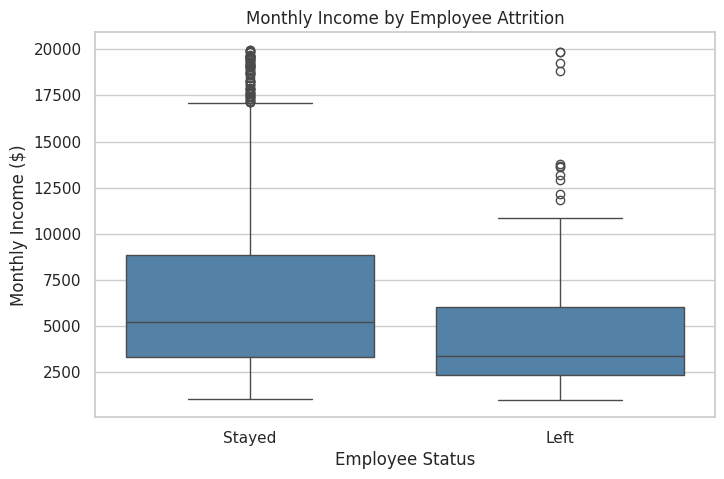

In [ ]:
# Compare monthly income for employees who stayed and employees who left.
print(train_df.groupby("Attrition")["MonthlyIncome"].describe())

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Attrition",
    y="MonthlyIncome",
    color="steelblue"
)

plt.title("Monthly Income by Employee Attrition")
plt.xlabel("Employee Status")
plt.ylabel("Monthly Income ($)")
plt.xticks([0, 1], ["Stayed", "Left"])
plt.show()


JobSatisfaction
1    22.08
2    17.59
3    16.38
4    11.20
Name: Attrition, dtype: float64


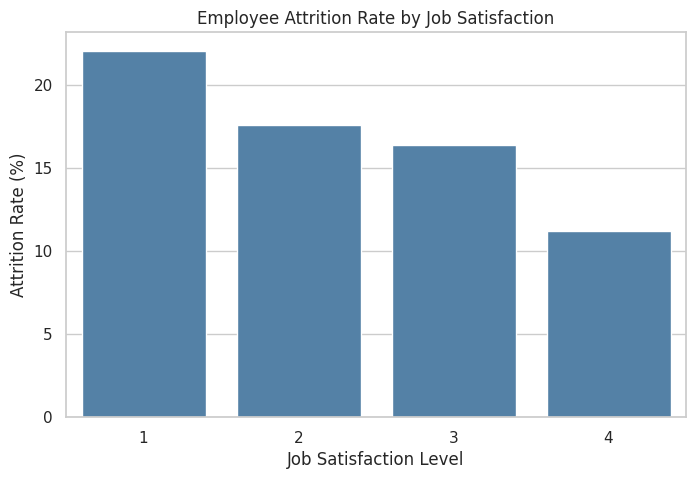

In [ ]:
# Compare attrition rates at each job satisfaction level.
satisfaction_attrition = (
    train_df.groupby("JobSatisfaction")["Attrition"].mean() * 100
)

print(satisfaction_attrition.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=satisfaction_attrition.index,
    y=satisfaction_attrition.values,
    color="steelblue"
)

plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.show()


YearsAtCompany
0-1 Years    38.55
2-4 Years    16.90
5-9 Years    11.66
10+ Years     9.43
Name: Attrition, dtype: float64


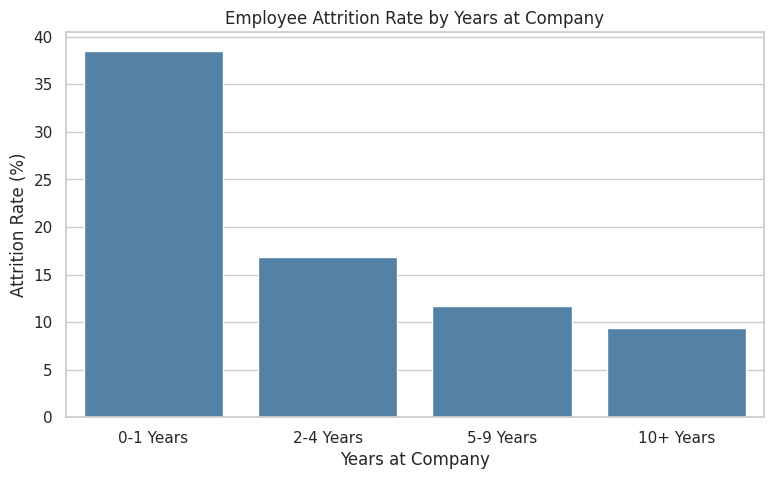

In [ ]:
# Group employees by years at the company and compare attrition rates.
tenure_groups = pd.cut(
    train_df["YearsAtCompany"],
    bins=[0, 2, 5, 10, np.inf],
    labels=["0-1 Years", "2-4 Years",
            "5-9 Years", "10+ Years"],
    right=False
)

tenure_attrition = (
    train_df.groupby(tenure_groups, observed=True)["Attrition"].mean() * 100
)

print(tenure_attrition.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    x=tenure_attrition.index,
    y=tenure_attrition.values,
    color="steelblue"
)

plt.title("Employee Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.show()


WorkLifeBalance
1    31.43
2    18.15
3    13.64
4    17.60
Name: Attrition, dtype: float64


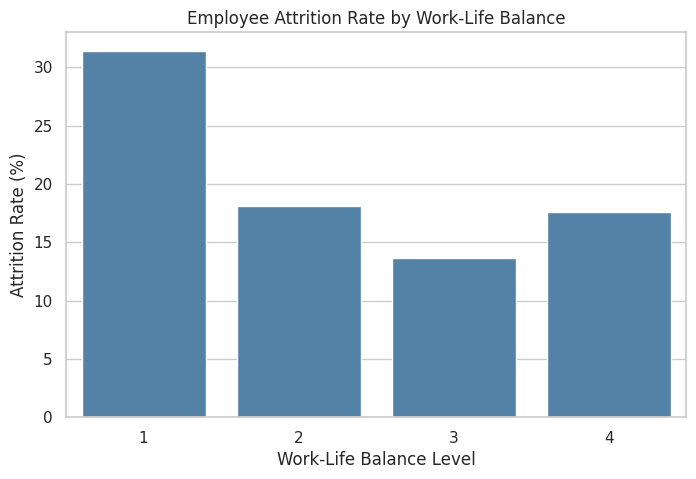

In [ ]:
# Compare attrition rates at each work-life balance level.
balance_attrition = (
    train_df.groupby("WorkLifeBalance")["Attrition"].mean() * 100
)

print(balance_attrition.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=balance_attrition.index,
    y=balance_attrition.values,
    color="steelblue"
)

plt.title("Employee Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Attrition Rate (%)")
plt.show()


## 4. Prepare the features for classification

Separate the target from the predictors. Standardize numerical columns and one-hot encode categorical columns. The preprocessing is fitted inside each model pipeline so that the test data stays separate.

In [23]:
# X contains the predictor columns; y contains the target column.
X_train = train_df.drop(columns=["Attrition"])
y_train = train_df["Attrition"]

X_test = test_df.drop(columns=["Attrition"])
y_test = test_df["Attrition"]

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training Features: (1176, 30)
Testing Features: (294, 30)

Training Class Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Class Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [24]:
# Identify categorical and numerical columns and set up preprocessing.
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", categorical_columns)
print("\nNumerical Features:", numerical_columns)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns)
    ]
)


Categorical Features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical Features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## 5. Train and tune the classification models

Compare Logistic Regression, Decision Tree and Random Forest. Use five-fold stratified cross-validation and choose the parameters that maximize the F1-score for employees who left. Compare balanced and unweighted settings.

In [26]:
# Import the classifiers, tuning tools and evaluation metrics.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)


In [28]:
# List the models and parameter values to test.
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        {
            "model__C": [0.01, 0.1, 1, 10],
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_leaf": [1, 5, 10],
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [5, 10, None],
            "model__min_samples_leaf": [1, 5],
            "model__class_weight": [None, "balanced"]
        }
    )
}


In [29]:
# Try each parameter combination using five-fold cross-validation.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
cv_results = []

for name, (model, parameters) in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        pipeline,
        parameters,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    # Fit preprocessing and the model on training folds only.
    grid_search.fit(X_train, y_train)

    # Save the best trained model for the final test.
    best_models[name] = grid_search.best_estimator_

    cv_results.append({
        "Model": name,
        "CV F1-Score": grid_search.best_score_
    })

    print("\nModel:", name)
    print("Best Parameters:", grid_search.best_params_)
    print("Best CV F1-Score:", round(grid_search.best_score_, 4))

    # Compare class weighting approaches
    tuning_results = pd.DataFrame(grid_search.cv_results_)

    tuning_results["Weighting"] = (
        tuning_results["param_model__class_weight"]
        .apply(lambda x: "Balanced" if x == "balanced"
               else "Unweighted")
    )

    print("Class Weight Comparison:")
    print(tuning_results.groupby("Weighting")
          ["mean_test_score"].max().round(4))



Model: Logistic Regression
Best Parameters: {'model__C': 1, 'model__class_weight': None}
Best CV F1-Score: 0.561
Class Weight Comparison:
Weighting
Balanced      0.4947
Unweighted    0.5610
Name: mean_test_score, dtype: float64

Model: Decision Tree
Best Parameters: {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 5}
Best CV F1-Score: 0.3914
Class Weight Comparison:
Weighting
Balanced      0.3764
Unweighted    0.3914
Name: mean_test_score, dtype: float64

Model: Random Forest
Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Best CV F1-Score: 0.4747
Class Weight Comparison:
Weighting
Balanced      0.4747
Unweighted    0.3280
Name: mean_test_score, dtype: float64


In [30]:
# Rank the models by their best cross-validation F1-score.
cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    by="CV F1-Score",
    ascending=False
)

display(cv_comparison.round(4))


,Model,CV F1-Score
0,Logistic Regression,0.5610
2,Random Forest,0.4747
1,Decision Tree,0.3914


## 6. Evaluate the models

Compare the tuned models with a majority-class baseline on the held-out test set. Use accuracy, precision, recall, F1-score, average precision and confusion matrices.

In [31]:
# Create a simple baseline that always predicts the most common class.
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)


DummyClassifier(strategy='most_frequent')

In [32]:
# Evaluate each model on the same test records.
evaluation_models = {
    "Baseline": baseline,
    **best_models
}

results = []

for name, model in evaluation_models.items():

    # Predict the class and the probability of attrition (class 1).
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0),
        "Recall": recall_score(
            y_test, predictions, zero_division=0),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0),
        "Average Precision": average_precision_score(
            y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,Average Precision
0,Baseline,0.8401,0.0000,0.0000,0.0000,0.1599
1,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.5836
2,Decision Tree,0.8231,0.4324,0.3404,0.3810,0.3416
3,Random Forest,0.8333,0.4750,0.4043,0.4368,0.4366


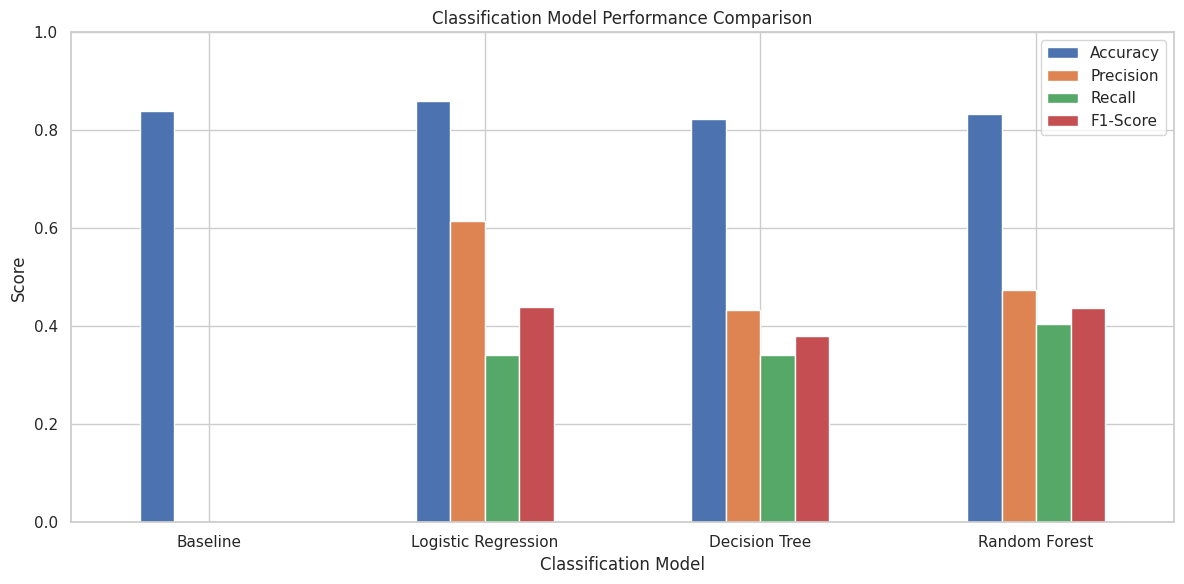

In [33]:
# Plot the main evaluation metrics side by side.
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


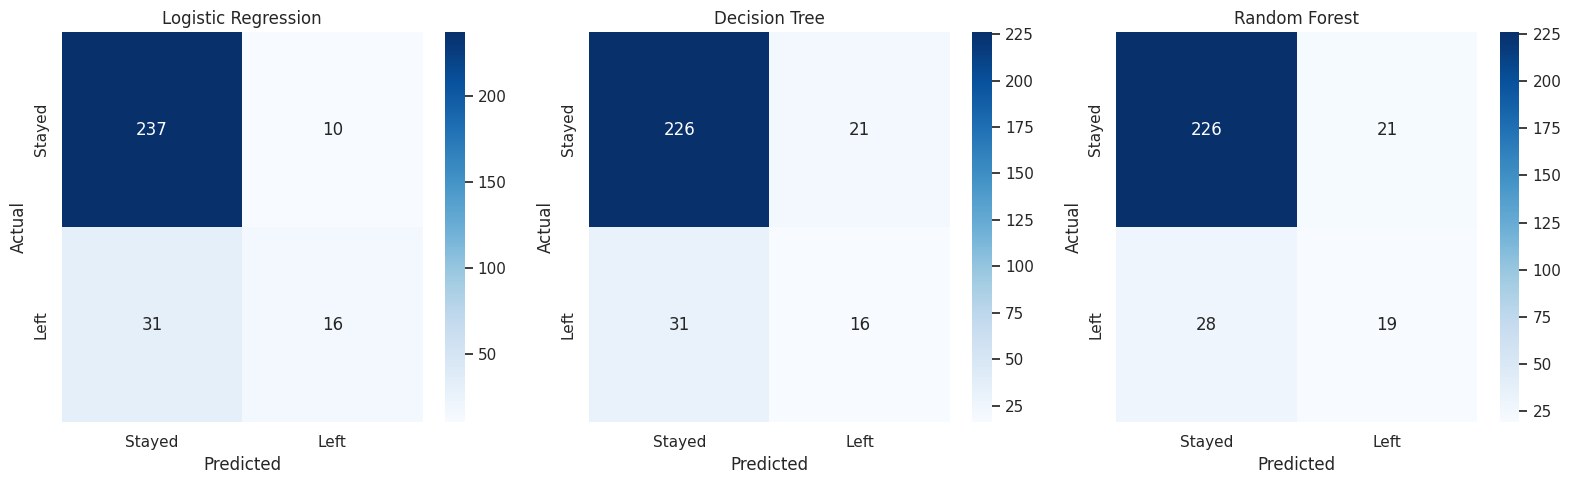

In [34]:
# Show actual vs. predicted employee status for each classifier.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, best_models.items()):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Left"],
        yticklabels=["Stayed", "Left"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 7. Interpret the results

Use Logistic Regression coefficients and Random Forest permutation importance to examine the predictors. These show associations, not causes. The test-set importance is for final interpretation, not further model tuning.

In [35]:
# Find the Logistic Regression coefficients with the largest absolute values.
# Retrieve the best Logistic Regression model
lr_model = best_models["Logistic Regression"]

# Extract feature names and coefficients
feature_names = lr_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = lr_model.named_steps["model"].coef_[0]

# Create coefficient dataframe
lr_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

lr_importance["Absolute Importance"] = (
    lr_importance["Coefficient"].abs()
)

lr_importance = lr_importance.sort_values(
    "Absolute Importance", ascending=False
)

display(lr_importance.head(15).round(4))


,Feature,Coefficient,Absolute Importance
42,cat__JobRole_Research Director,-1.0341,1.0341
39,cat__JobRole_Laboratory Technician,1.0303,1.0303
49,cat__OverTime_No,-0.9288,0.9288
23,cat__BusinessTravel_Non-Travel,-0.9164,0.9164
50,cat__OverTime_Yes,0.9161,0.9161
24,cat__BusinessTravel_Travel_Frequently,0.8981,0.8981
45,cat__JobRole_Sales Representative,0.8803,0.8803
33,cat__EducationField_Other,-0.7151,0.7151
29,cat__EducationField_Human Resources,0.5997,0.5997
37,cat__JobRole_Healthcare Representative,-0.5793,0.5793


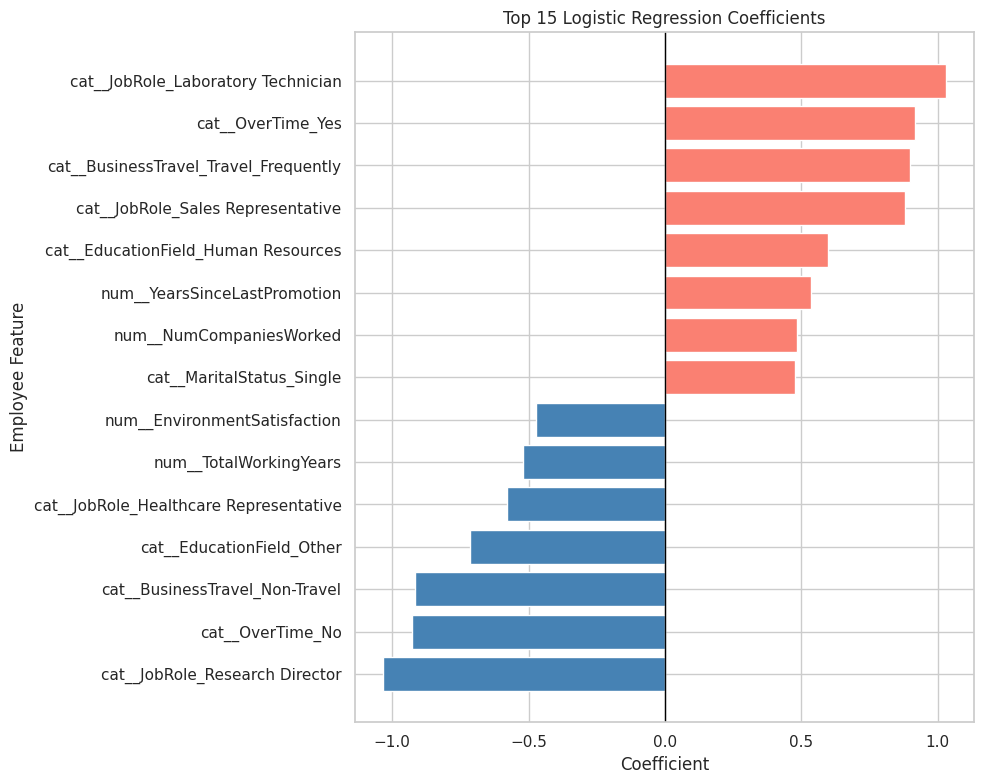

In [36]:
# Plot positive and negative coefficients in different colors.
top_features = lr_importance.head(15).sort_values(
    "Coefficient"
)

colors = [
    "salmon" if value > 0 else "steelblue"
    for value in top_features["Coefficient"]
]

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Employee Feature")
plt.tight_layout()
plt.show()


In [37]:
# Shuffle each feature and measure the drop in average precision.
from sklearn.inspection import permutation_importance

rf_model = best_models["Random Forest"]

# Calculate permutation importance
rf_permutation = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="average_precision",
    n_jobs=-1
)

rf_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_permutation.importances_mean,
    "Standard Deviation": rf_permutation.importances_std
})

rf_importance = rf_importance.sort_values(
    "Importance", ascending=False
)

display(rf_importance.head(15).round(4))


,Feature,Importance,Standard Deviation
18,OverTime,0.1455,0.0226
22,StockOptionLevel,0.0184,0.0129
13,JobSatisfaction,0.0177,0.0060
1,BusinessTravel,0.0155,0.0051
14,MaritalStatus,0.0113,0.0092
11,JobLevel,0.0111,0.0165
7,EnvironmentSatisfaction,0.0103,0.0078
15,MonthlyIncome,0.0081,0.0200
3,Department,0.0066,0.0046
28,YearsSinceLastPromotion,0.0052,0.0045


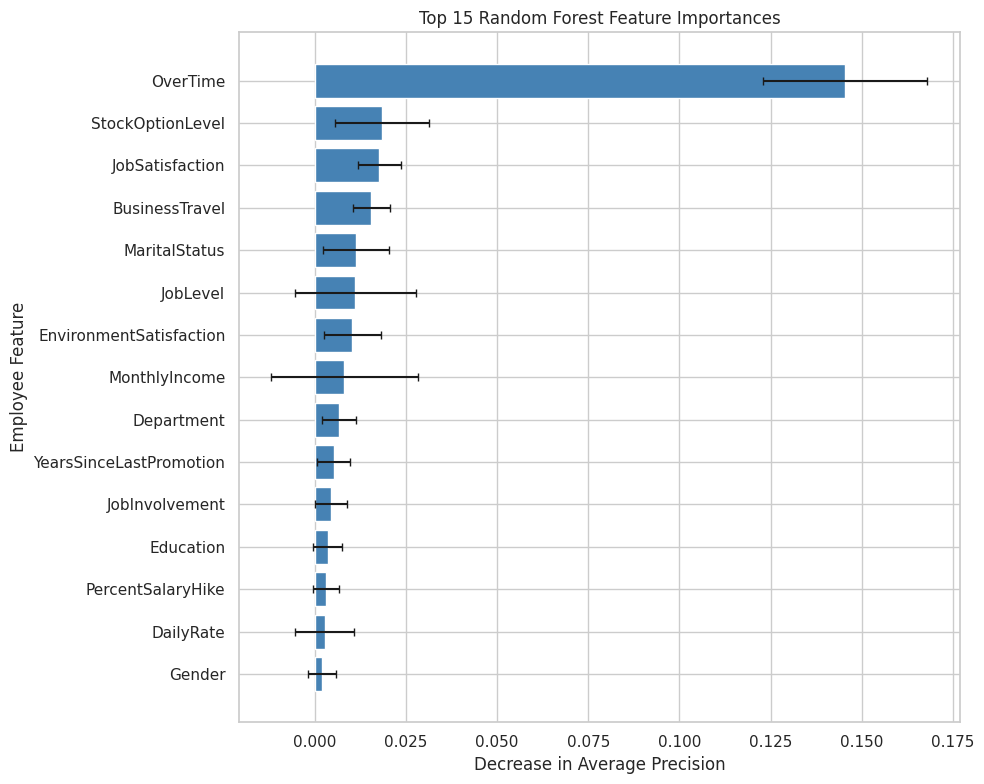

In [38]:
# Plot the top Random Forest features and their importance variability.
top_rf_features = rf_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_rf_features["Feature"],
    top_rf_features["Importance"],
    xerr=top_rf_features["Standard Deviation"],
    color="steelblue",
    capsize=3
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Decrease in Average Precision")
plt.ylabel("Employee Feature")
plt.tight_layout()
plt.show()


In [39]:
# Compare the five employee factors highlighted in the project proposal.
selected_features = [
    "OverTime",
    "JobSatisfaction",
    "MonthlyIncome",
    "YearsAtCompany",
    "WorkLifeBalance"
]

selected_importance = rf_importance[
    rf_importance["Feature"].isin(selected_features)
]

display(selected_importance.round(4))

selected_lr = lr_importance[
    lr_importance["Feature"].str.contains(
        "|".join(selected_features)
    )
]

display(selected_lr.round(4))


,Feature,Importance,Standard Deviation
18,OverTime,0.1455,0.0226
13,JobSatisfaction,0.0177,0.0060
15,MonthlyIncome,0.0081,0.0200
25,WorkLifeBalance,-0.0012,0.0031
26,YearsAtCompany,-0.0306,0.0130


,Feature,Coefficient,Absolute Importance
49,cat__OverTime_No,-0.9288,0.9288
50,cat__OverTime_Yes,0.9161,0.9161
8,num__JobSatisfaction,-0.4125,0.4125
18,num__WorkLifeBalance,-0.3003,0.3003
19,num__YearsAtCompany,0.1586,0.1586
9,num__MonthlyIncome,-0.1387,0.1387
